# Capital Asset Pricing Model (CAPM)
---
**CAPM:**  
$$
E(R_i) = R_f + \beta_i \big( E(R_m) - R_f \big)
$$  

where  

$$
E(R_i) = \text{expected return of asset $i$} \\
R_f = \text{risk-free rate} \\
\beta_i = \text{beta of asset $i$ (systematic risk)} \\
E(R_m) = \text{expected return of the market portfolio}
$$  

---

**Beta definition:**  

$$
\beta_i = \frac{\text{Cov}(R_i, R_m)}{\text{Var}(R_m)}
$$  

where  

$$
\text{Cov}(R_i, R_m) = \text{covariance between asset $i$ and market returns} \\
\text{Var}(R_m) = \text{variance of market returns}\\
$$

Basically
$$
\text{Var}(R_m) = \text{Cov}(R_m, R_m)
$$


## Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [59]:
ticker = yf.download("IBM", "2010-01-01", "2017-01-01", auto_adjust=False)
# ticker = ticker.resample("ME").last()
ticker

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,IBM,IBM,IBM,IBM,IBM,IBM
Date,,,,,,
2010-01-04,73.283356,126.625237,127.122368,125.095604,125.411087,6438444
2010-01-05,72.398041,125.095604,126.051628,124.378586,125.889099,7156104
2010-01-06,71.927780,124.282982,125.707458,124.101341,124.933075,5863144
2010-01-07,71.678787,123.852776,124.521988,123.240921,124.158699,6109268
2010-01-08,72.398041,125.095604,125.162521,123.374763,123.393883,4390271
...,...,...,...,...,...,...
2016-12-23,108.803223,159.378586,160.124283,159.130020,159.655838,1779455
2016-12-27,109.083817,159.789673,160.592728,159.512421,159.636703,1461785


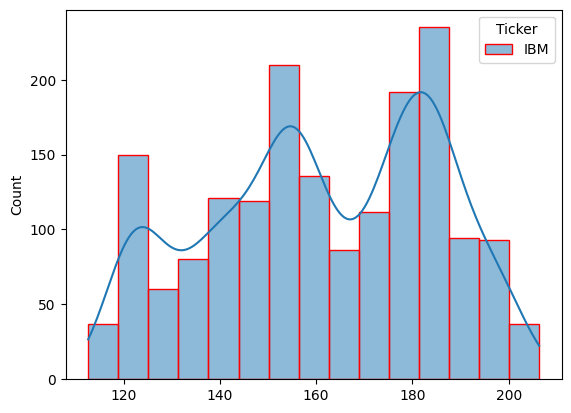

In [66]:
# plt.hist(ticker['Close'])
import seaborn as sns

sns.histplot(ticker['Close'],kde=True, color='lightgreen', edgecolor='red')
plt.show()

In [31]:
ticker['Adj Close']

Ticker,IBM
Date,
2024-01-02,152.777466
2024-01-03,151.453079
2024-01-04,152.172028
2024-01-05,150.563858
2024-01-08,152.436905
...,...
2025-09-29,279.799988
2025-09-30,282.160004
2025-10-01,286.489990


In [34]:
ticker = yf.Ticker("IBM")
data = ticker.history(start="2024-01-01", end="2025-10-04")['Close']

In [35]:
data

Date
2024-01-02 00:00:00-05:00    152.777466
2024-01-03 00:00:00-05:00    151.453079
2024-01-04 00:00:00-05:00    152.172028
2024-01-05 00:00:00-05:00    150.563858
2024-01-08 00:00:00-05:00    152.436905
                                ...    
2025-09-29 00:00:00-04:00    279.799988
2025-09-30 00:00:00-04:00    282.160004
2025-10-01 00:00:00-04:00    286.489990
2025-10-02 00:00:00-04:00    286.720001
2025-10-03 00:00:00-04:00    288.369995
Name: Close, Length: 441, dtype: float64

In [3]:
type(ticker)

pandas.core.frame.DataFrame

$$
\beta = \text{1} \text{: stock moving exactly with the market}\\
\beta > \text{1} \text{: stock market risk is higher than that of an average stock}\\
\beta < \text{1} \text{: stock market risk is lower than that of an average stock}
$$

In [67]:
RISK_FREE_RATE = 0.05 # market interest rate
MONTHS_IN_YEAR = 12 # Monthly Returns -> Annual Returns

class CAPM:
    def __init__(self, stocks, start_date, end_date):
        self.stocks = stocks
        self.start_date = start_date
        self.end_date = end_date

    def download_data(self):
        data = {}

        for stock in self.stocks:
            ticker = yf.Ticker(stock)
            data[stock] = ticker.history(start=self.start_date, end=self.end_date)['Close']
        return pd.DataFrame(data)
    
    def initialize(self):
        stock_data = self.download_data()
        stock_data = stock_data.resample("ME").last()
        
        self.data = pd.DataFrame(
            {
                "s_close": stock_data[self.stocks[0]],
                "m_close": stock_data[self.stocks[1]]
            }
        )

        self.data[['s_returns', 'm_returns']] = np.log(
            self.data[['s_close', 'm_close']]
         / self.data[['s_close', 'm_close']].shift(1))

        self.data = self.data.dropna()
        # print(self.data)
    
    def calculate_beta(self):
        # Covariance Matrix: The diagonal items are the variances
        # off diagonals are the covariances
        # the matrix is symmetrix: cov[0, 1] = cov[1, 0] 
        covariance_matrix = np.cov(self.data["s_returns"], self.data["m_returns"])
        beta = covariance_matrix[0, 1] / covariance_matrix[1,1]
        print(covariance_matrix, beta)

    def plot_regression(self, alpha, beta):
        fig, axis = plt.subplots(1, figsize=(20, 10))
        axis.scatter(self.data['m_returns'], self.data['s_returns'], label="Data Points")
        axis.plot(self.data['m_returns'], beta * self.data['m_returns'] + alpha, color="red", label="CAPM Line")
        plt.title("Capital Asset Pricing Model, finding alphas and betas")
        plt.xlabel("Market return $R_m$", fontsize=18)
        plt.ylabel("Stock Return $R_a$")
        # plt.text(0.08, 0.05, r"$R_a = \beta * R_m + \alpha$", fontsize=18)
        plt.text(0.00275, 0.05, r"$R_a = \beta * R_m + \alpha$", fontsize=18)
        plt.legend()
        plt.grid(True)
        plt.show()

    def regression(self):
        # using Linear Regression to fit a line to the data
        # [stock_returns, market_returns] - slope is the beta
        beta, alpha = np.polyfit(self.data['m_returns'], self.data['s_returns'], deg=1)
        print(f"Beta from Regression: {beta}")
        print(f"Alpha from Regression: {alpha}")
        # Calculate the Expected Return according to CAPM Formula
        # We are after Annual Return (x12)
        expected_returns = RISK_FREE_RATE + beta * (
            self.data['m_returns'].mean() * MONTHS_IN_YEAR - RISK_FREE_RATE
        )
        # E[ra] = rf + Ba(E[rm] - rf)
        print(expected_returns)
        self.plot_regression(alpha, beta)
        

[[0.00533166 0.00198798]
 [0.00198798 0.00255414]] 0.7783361687197489
Beta from Regression: 0.7783361687197494
Alpha from Regression: 0.006131541437930402
0.11035385044491423


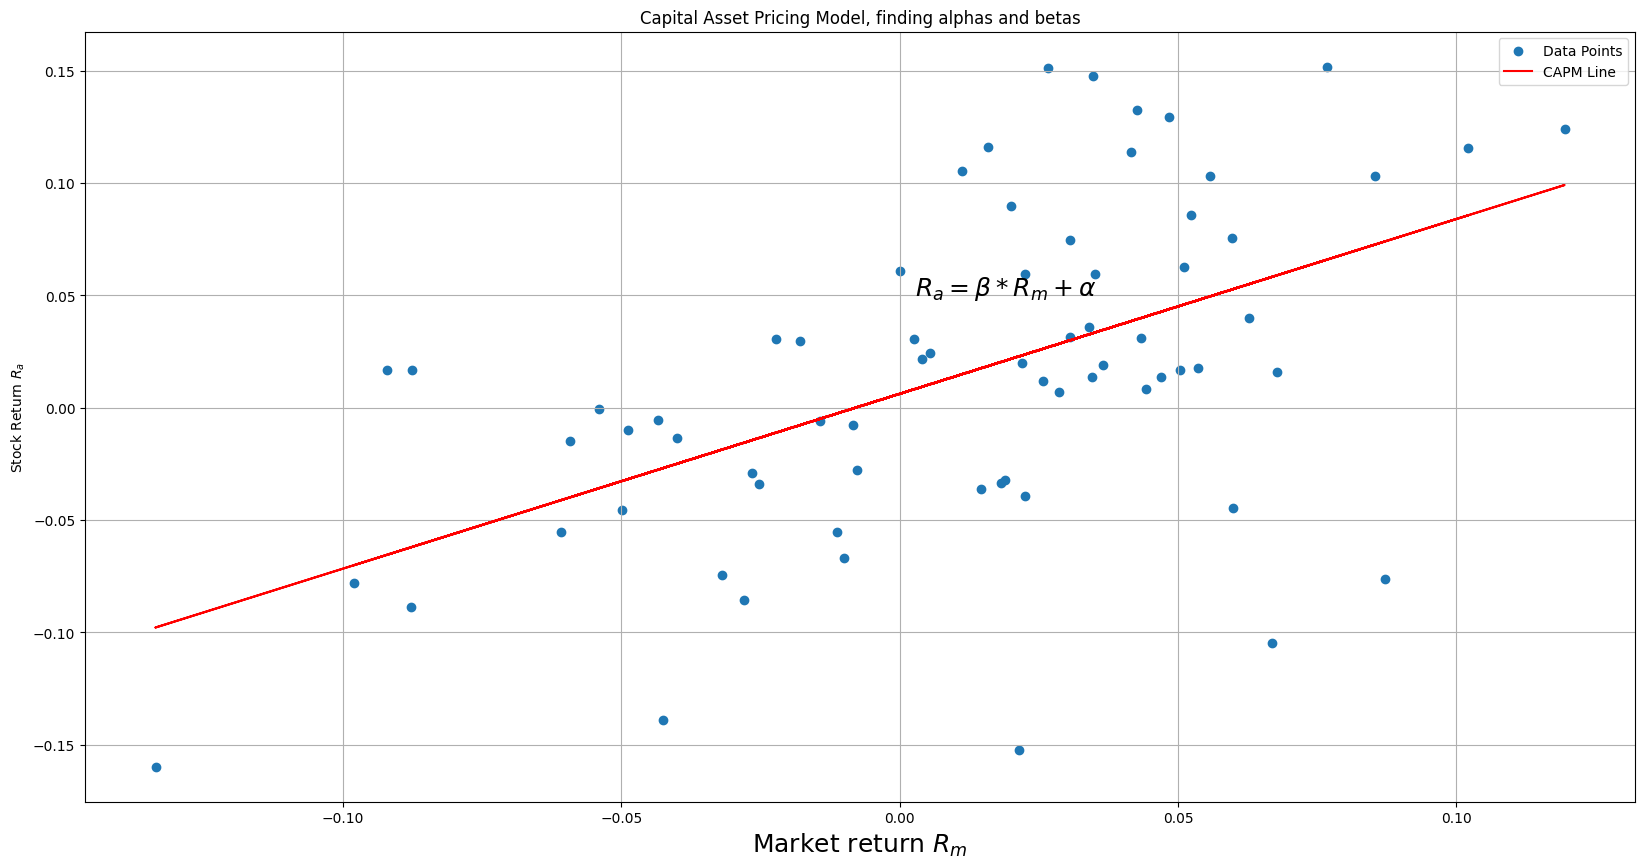

In [68]:
stocks = ["IBM", "^GSPC"]
start_date = "2020-01-01"
end_date = "2025-10-04"
capm = CAPM(stocks, start_date, end_date)
capm.initialize()
capm.calculate_beta()
capm.regression()

# Normal Distribution

C:\Users\shash\AppData\Local\Temp\ipykernel_4644\1718543340.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  ticker = yf.download(self.stock, self.start_date, self.end_date)
[*********************100%***********************]  1 of 1 completed

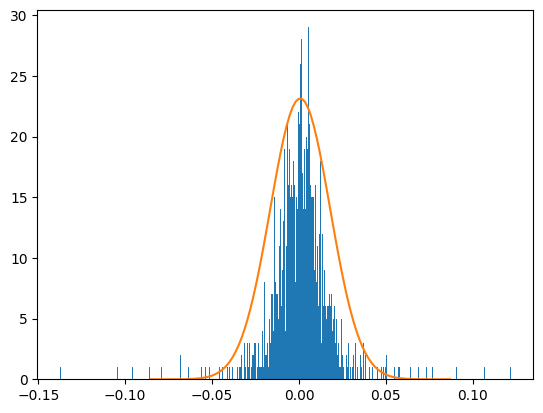

In [ ]:
from scipy.stats import norm
class NormalDistribution:
    def __init__(self, stock: str, start_date, end_date):
        self.stock = stock
        self.start_date = start_date
        self.end_date = end_date

    def download_data(self):
        ticker = yf.download(self.stock, self.start_date, self.end_date)
        return pd.DataFrame(ticker)
    
    def calculate_returns(self):
        stock_data = self.download_data()
        stock_data['Price'] = np.log(stock_data['Close'] / stock_data['Close'].shift(1))
        self.stock_data = stock_data.dropna()

    # The fat tails mean that extreme events occur more frequently in reality
    # than what a normal distribution would predict
    def show(self):
        plt.hist(self.stock_data['Price'], bins=700)
        stock_variance = self.stock_data['Price'].var()
        stock_mean = self.stock_data['Price'].mean()
        sigma = np.sqrt(stock_variance)

        x = np.linspace(stock_mean - 5 * sigma, stock_mean + 5 * sigma, 100)
        plt.plot(x, norm.pdf(x, stock_mean, sigma))
        plt.show()

nd = NormalDistribution("IBM", "2020-01-01", "2025-10-04")
nd.calculate_returns()
nd.show()

C:\Users\shash\AppData\Local\Temp\ipykernel_4644\1718543340.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  ticker = yf.download(self.stock, self.start_date, self.end_date)
[*********************100%***********************]  1 of 1 completed


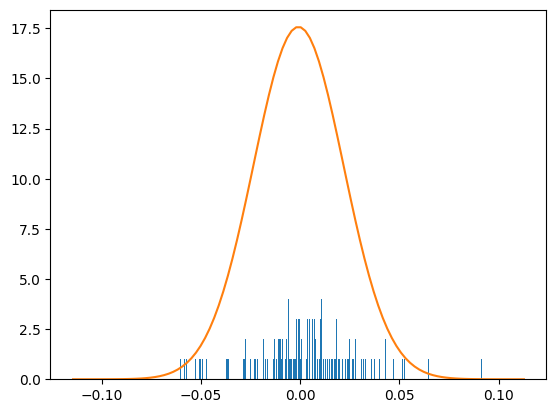

In [99]:
nd = NormalDistribution("IBM", "2008-01-01", "2008-12-31")
nd.calculate_returns()
nd.show()